Βρέθηκαν 328 άστρα για την MDI-1.
Βρέθηκαν 328 άστρα για την MDI-2.


C:\Users\Maria Tsianti\AppData\Local\Temp\ipykernel_10364\1152590565.py:125: UserWarning: Ignoring specified arguments in this call because figure with num: 1 already exists
  plt.figure(1, figsize=(10, 6))
C:\Users\Maria Tsianti\AppData\Local\Temp\ipykernel_10364\1152590565.py:129: UserWarning: Ignoring specified arguments in this call because figure with num: 2 already exists
  plt.figure(2, figsize=(10, 6))


Βρέθηκαν 328 άστρα για την SkI4.
Βρέθηκαν 328 άστρα για την NLD.
Βρέθηκαν 328 άστρα για την MDI-3.
Βρέθηκαν 328 άστρα για την MDI-4.
Βρέθηκαν 328 άστρα για την HHJ-1.
Βρέθηκαν 328 άστρα για την HLPS-3.
Βρέθηκαν 328 άστρα για την W.
Βρέθηκαν 328 άστρα για την PS.


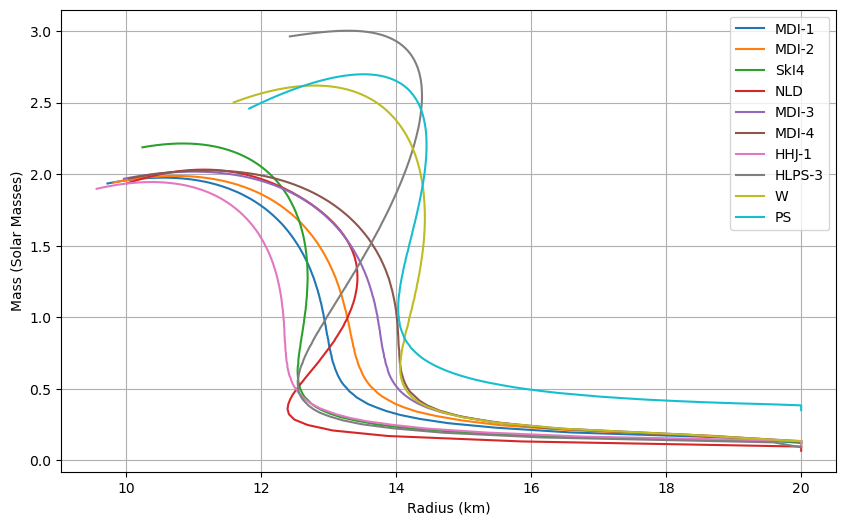

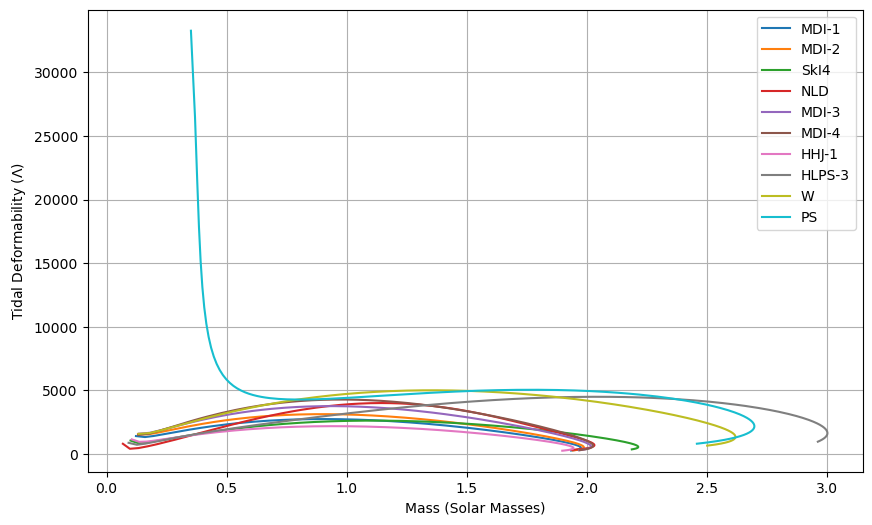

In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Defining the EoS
def epsilon(P, eos_name):
    P = np.maximum(P, 0)
    if eos_name == 'MDI-1':
        eps_core = 4.1844 * P**0.81449 + 95.00135 * P**0.31736
    elif eos_name == 'MDI-2':
        eps_core = 5.97365 * P**0.77374 + 89.24 * P**0.30993
    elif eos_name == 'MDI-3':
        eps_core = 15.55 * P**0.666 + 76.71 * P**0.247
    elif eos_name == 'MDI-4':
        eps_core = 25.99587 * P**0.61209 + 65.62193 * P**0.15512
    elif eos_name == 'SkI4':
        eps_core = 4.75668 * P**0.76537 + 105.722 * P**0.2745
    elif eos_name == 'NLD':
        eps_core = 119.05736 + 304.80445 * (1 - np.exp(- P / 48.61465)) + 33722.34448 * (1 - np.exp(- P / 17499.47411))
    elif eos_name == 'HHJ-1':
        eps_core = 1.78439 * P**0.93761 + 106.93652 * P**0.31715
    elif eos_name == 'HLPS-3':
        eps_core = 131.811 * (1 - np.exp(- P / 4.41577)) + 924.143 * (1 - np.exp(- P / 523.736)) + 81.5682
    elif eos_name == 'W':
        eps_core = 0.261822 * P**1.16851 + 92.4893 * P**0.307728
    elif eos_name == 'PS':
        eps_core = 1.69483 + 9805.95 * (1 - np.exp(- P * 0.000193624)) + 212.072 * (1 - np.exp(- P * 0.401508))
    else:
        eps_core = 0.0
    
    if P > 0.184:
        epsilon = eps_core
    elif P > 9.34375 * 10**-5 and P <= 0.184:
        epsilon = 0.00873 + 103.17338 * (1 - np.exp(- P / 0.38527)) + 7.34979 * (1 - np.exp(- P / 0.01211))
    elif P > 4.1725 * 10**-8 and P <= 9.34375 * 10**-5:
        epsilon = 0.00015 + 0.00203 * (1 - np.exp(- P * 344827.5)) + 0.10851 * (1 - np.exp(- P * 7692.3076))                                                                        
    elif P > 1.44875 * 10**-11 and P <= 4.1725 * 10**-8:
        epsilon = 0.0000051 * (1 - np.exp(- P * 0.2373 * 10**10)) + 0.00014 * (1 - np.exp(- P * 0.4020 * 10**8))                                                                       
    else:
        epsilon = 0.0
    return epsilon

# Defining the derivative of the EoS
def get_deps_dP(P, eos_name):
    h = 10**-6
    eps_plus = epsilon(P + h, eos_name)
    eps_minus = epsilon(max(P - h, 0.0), eos_name)
    derivative = (eps_plus - eps_minus) / (2 * h)

    return max(derivative, 10**-15)


# Defining the central pressure values
pressures_dense = np.arange(1, 50, 0.5)

pressures_sparse = np.arange(50, 1200, 5)

pressures = np.concatenate((pressures_dense, pressures_sparse))


# Defining the TOV system
def tov_system(r, variables, eos_name, G = 1, c = 1): # G=c=1
    P, M, y = variables
    
    P = max(P, 10**-15)
    M = max(M, 10**-15)
    
    eps = epsilon(P, eos_name) + 10**-15

    deps_dP = get_deps_dP(P, eos_name)
    dP_deps = 1.0 / deps_dP

    # TOV equation dP/dr
    dp_dr = - 1.474 * (eps / r**2) * (1 + P / eps) * (M + 11.2 * 10**-6 * r**3 * P) / (1 - 2.948 * M / r)

    # TOV equation dM/dr
    dm_dr = 11.2 * 10**-6 * r**2 * eps

    # TOV equation dy/dr
    e_l = 1 / (1 - (2.948 * M / r))
    Q = e_l * (11.2 * 10**-6 * (5 * eps + 9 * P + (eps + P) * deps_dP) - 6 / r**2)
    dy_dr = - y**2 / r - y * e_l / r * (1 + 11.2 * 10**-6 * r**2 * (P - eps)) - r * Q

    return [dp_dr, dm_dr, dy_dr]

# Integral termination 
def surface_events(r, variables, G = 1, c = 1):
    P, M , y = variables
    return P - 1.45 * 10**-11
surface_events.terminal = True

eos = ['MDI-1', 'MDI-2', 'SkI4', 'NLD', 'MDI-3', 'MDI-4', 'HHJ-1', 'HLPS-3', 'W', 'PS']

for current_eos in eos:
    masses = []
    radii = []
    lamdas = []
    
    # Creating the loop 
    for P_c in pressures:
        r_0 = 10**-3
        eps_c = epsilon(P_c, current_eos)
        m_0 = (11.2 * 10**-6 / 3) * r_0**3 * eps_c 
        r_max = 20 # Radius is measured in km
        solution = solve_ivp(tov_system, [r_0, r_max], [P_c, m_0, 2.0], events = surface_events, args=(current_eos,), rtol = 10**-9, atol = 10**-12) # Calling the function


        # Saving the radius and total mass
        if len(solution.t) > 1:
            R_final = solution.t[-1]
            M_final = solution.y[1][-1]
            y_final = solution.y[2][-1]

            C = 1.474 * M_final / R_final
            y_R = y_final 
            k2 = 8 * C**5 * (1 - 2 * C) * (2 - y_R + 2 * C * (y_R - 1)) * (2 * C * (6 - 3 * y_R + 3 * C * (5 * y_R - 8)) + 4 * C**3 * (13 - 11 * y_R + C * (3 * y_R -2) + 2 * C**2 * (1 + y_R)) + 3 * (1 - 2 * C)**2 * (2 - y_R + 2 * C * (y_R - 1)) * np.log(1 -2 * C))**-1 / 5
            lamda = 2 * M_final**5 * k2 / (3 * C**5)
            
            radii.append(R_final)
            masses.append(M_final)
            lamdas.append(lamda)
    
    print(f"Βρέθηκαν {len(radii)} άστρα για την {current_eos}.")
    if len(radii) > 0:
        plt.figure(1, figsize=(10, 6))
        plt.plot(radii, masses, label=current_eos)
    
    if len(lamdas) > 0:
        plt.figure(2, figsize=(10, 6))
        plt.plot(masses, lamdas, label=current_eos)
    
# Creating the mass-radius diagram
plt.figure(1)
plt.xlabel("Radius (km)")
plt.ylabel("Mass (Solar Masses)")
plt.grid(True)
plt.legend()

plt.figure(2)
plt.xlabel("Mass (Solar Masses)")
plt.ylabel("Tidal Deformability ($\Lambda$)")
plt.grid(True)
plt.legend()

plt.show()